# _Hands-on activity #2_

Learning goals:
1. Obtain data from an online database using its API and xarray functionality
2. Use matplotlib to make different types of plots (line, contour, scatter)

### To serve as a reference, code outputs are provided.

### First, let's import the necessary packages.

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
from datetime import datetime

### Now, please obain global temperature data using Xarray from http://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCEP-NCAR/.CDAS-1/.MONTHLY/.Diagnostic/.surface/.temp/dods

### <span style="color:blue"> Solution Notes: `Xarray` allows you to open datasets from URLs. In this case, the only unique addition is that the timestamps should not be decoded due to their unique format that will otherwise throw an error.

In [2]:
ds_url = 'http://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCEP-NCAR/.CDAS-1/.MONTHLY/.Diagnostic/.surface/.temp/dods'
ds = xr.open_dataset(ds_url, decode_times=False)

### Now, extract the longitude, latitude, and temperature, and convert from Kelvin to Celcius.

### <span style="color:blue"> Solution Notes: The dataset coordinates/dimensions are displayed for reference, and can be pulled through the `dim.values` method.

In [3]:
ds

<xarray.Dataset>
Dimensions:  (Y: 94, X: 192, T: 895)
Coordinates:
  * Y        (Y) float32 88.54 86.65 84.75 82.85 ... -82.85 -84.75 -86.65 -88.54
  * X        (X) float32 0.0 1.875 3.75 5.625 7.5 ... 352.5 354.4 356.2 358.1
  * T        (T) float32 -131.5 -130.5 -129.5 -128.5 ... 759.5 760.5 761.5 762.5
Data variables:
    temp     (T, Y, X) float32 ...
Attributes:
    Conventions:  IRIDL

In [4]:
temp = ds.temp[-1].values - 273.15
lon = ds.X.values
lat = ds.Y.values

### Now, Create a contour map of the wold temperatures that looks similar to https://imgur.com/ibuj0cM

### <span style="color:blue"> Solution Notes: The main purpose of this portion is to get used to the `matplotlib` abilities, and similarity to MatLab. We create a filled and normal countour, create a grid and colorbar for better reference, and label the axes. Addiitonal coloring/design options could also be added. Exact outputs may look different, as the data is periodically updated.

Text(0, 0.5, 'Latitude')

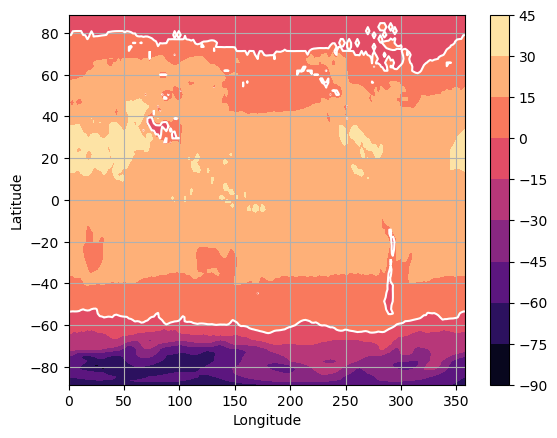

In [5]:
plt.contourf(lon,lat,temp,cmap="magma")
plt.grid()
plt.colorbar()
plt.contour(lon,lat,temp,colors="white",levels=[0])
plt.xlabel("Longitude")
plt.ylabel("Latitude")

### Now, calculate the average temperature as a function of latitude along a profile from the north pole to the south pole.

### <span style="color:blue"> Solution Notes: I chose an arbitrary longitude through `ds.sel`, extracted the values similarly to above, and converted them.

In [6]:
vals = ds.sel(X=135)
temp_slice = vals.temp[-1].values - 273.15

### Plot the profile. It should look something like this: https://imgur.com/a/iPEUKyv

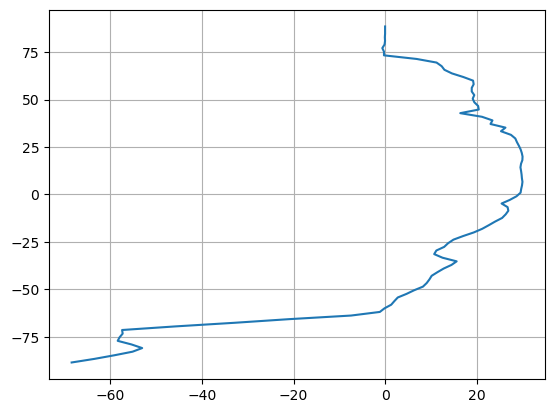

In [7]:
plt.plot(temp_slice,vals.Y)
plt.grid()

### Now let's get a dataset from a public data server using the Application Programming Interface, or API.

#### Find the latitude and longitude for Shishaldin volcano

In [8]:
lat = 63.9
lon = -22

### Now, obtain data for the earthquakes beneath Shishaldin for 2023 from the USGS using the API: https://earthquake.usgs.gov/fdsnws/event/1/

Many options are given, so we recommend bounding only by time, lat/lon, and setting a circular radius around Shishaldin. We recommend the `request` library, and a geojson format, though others are viable.

### <span style="color:blue"> Solution Notes: After digging around the website, you should find how to properly format a request, starting with `https://earthquake.usgs.gov/fdsnws/event/1/query?`. The format should be geojson for easy reading. The start and end times must also be correctly formatted according to the USGS. Next, the latitude and longitude selecteed can be input. For ease of use, it's best to use the `maxradiuskm` value, and set it to a reasonable value, which i chose as 20 here. <br><br> The next cell uses the requests library to pull the data, and write it into a proper JSON file. 

In [9]:
start_time = "2023-01-01"

end_time = "2023-07-19"

req_url = f"""https://earthquake.usgs.gov/fdsnws/event/1/query?format=geojson&starttime={start_time}&endtime={end_time}&latitude={lat}&longitude={lon}&maxradiuskm=20"""

In [10]:
r = requests.get(req_url)
with open("data.json","w") as f:
    f.write(r.text)

In [12]:
data = r.json()
coords = []

## How many earthquakes in the dataset you downloaded?

In [13]:
len(data["features"])

10

### <span style="color:blue"> Solution Notes: Once read into a JSON variable, it is necessary to pull out a few values. In a for loop, each earthquake has its coordinates and timestamp (epoch time converted from milliseconds to seconds) put into an array. The `coords` variable is a matrix of all earthquake data we need. To be able to plot based on time, we must reformat the values to be compatible with `matplotlib`.

In [14]:
for eq in data["features"]:
    elem = np.append(eq["geometry"]["coordinates"],datetime.fromtimestamp(eq["properties"]["time"]/1000))
    coords.append(elem)
coords = np.array(coords)
t = [mdates.date2num(coords[:,3])]

### Finally, create a 3D scatter plot showing the locations of the earthquakes under the volcano. Color the spots by date. It should look something like this:

### <span style="color:blue"> Solution Notes: Make sure to set the projection to `3d` for this specific plot. To colorcode, the c (color) variable must be set to the `t` variable with the special formatting. Assign the scatter plot to a variable to be able to link a colorbar to it.

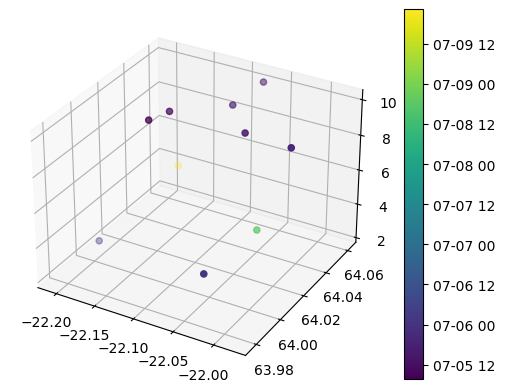

In [15]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
sc = ax.scatter(coords[:,0],coords[:,1],coords[:,2],c=t)
loc = mdates.AutoDateLocator()
fig.colorbar(sc, ticks=loc,
                 format=mdates.AutoDateFormatter(loc))